# Detección de defectos en infraestructuras (`Corrosion-bi3q3`) con Faster R-CNN v2

**Asignatura:** Visión por Computador — USC (2026/2027)  
**Dataset asignado:** `Francesco/corrosion-bi3q3` (Roboflow-100, partición corregida `slippage_validation_split`)  
**Detector analizado:** Faster R-CNN v2 (`fasterrcnn_resnet50_fpn_v2`, pesos `COCO_V1` de `torchvision`)

Este cuaderno reúne los resultados, gráficas y análisis necesarios para la **exposición oral**, siguiendo la estructura del guion:
1. Descripción del dataset y del detector Faster R-CNN v2.
2. Metodología y resultados del **baseline** (curvas de entrenamiento, mAP, curvas PR y tiempos de inferencia).
3. **Estrategias de mejora propuestas** (hipótesis técnicas y modificaciones).
4. **Evolución y comparativa cuantitativa en validación** + **análisis de resultados por técnica**.
5. **Análisis cualitativo** (aciertos, fallos frecuentes y comparativa *Baseline vs Mejor modelo*).
6. Preparación del **Ensemble WBF** con RetinaNet v2.
7. **Evaluación final en `test`** (configuraciones seleccionadas en validación) y conclusiones.

In [1]:
import json
import sys
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from matplotlib.patches import Rectangle

# Localizar la raíz del proyecto tanto desde la raíz como desde notebooks/
RAIZ = Path.cwd()
if not (RAIZ / "src").exists():
    RAIZ = RAIZ.parent
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

from src.dataset import CorrosionDataset, NOMBRES_CLASES, PARTICIONES
from src.evaluar import cargar_predicciones, _iou_entre_cajas

DIR_RESULTADOS = RAIZ / "results" / "slippage_validation_split"
DIR_FIGURAS = DIR_RESULTADOS / "figuras"
DIR_FIGURAS.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 200,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 10,
})

COLORES_CLASE = {
    1: "#1f77b4",  # Slippage
    2: "#d62728",  # corrosion
    3: "#ff7f0e",  # crack
}

NOMBRE_BASELINE = "Baseline (Faster R-CNN v2)"
EXPERIMENTOS = {
    NOMBRE_BASELINE: {
        "dir": DIR_RESULTADOS / "faster_rcnn",
        "categoria": "Baseline",
    },
    "E1: Data Augmentation": {
        "dir": DIR_RESULTADOS / "exp01_data_augmentation",
        "categoria": "Aumento de datos",
    },
    "E2: Transfer Learning": {
        "dir": DIR_RESULTADOS / "exp02_transfer_learning",
        "categoria": "Transfer learning",
    },
    "E3a: SGD + MultiStepLR": {
        "dir": DIR_RESULTADOS / "exp03_sgd_multistep",
        "categoria": "Optimizador",
    },
    "E3b: Anchors pequeños + 960 px": {
        "dir": DIR_RESULTADOS / "exp04_anchors_resolucion",
        "categoria": "Anchors / Resolución",
    },
    "E4: Pérdida CIoU + CE ponderada": {
        "dir": DIR_RESULTADOS / "exp05_perdidas_ciou_ponderada",
        "categoria": "Funciones de pérdida",
    },
    "E5a: Ajuste NMS + Confianza": {
        "dir": DIR_RESULTADOS / "exp06_postprocesado_nms",
        "categoria": "Post-procesado",
    },
    "E5b: TTA WBF (orig + hflip)": {
        "dir": DIR_RESULTADOS / "exp07_tta_wbf",
        "categoria": "Inferencia (TTA)",
    },
    "E6: Ensemble WBF (Faster R-CNN)": {
        "dir": DIR_RESULTADOS / "exp08_ensemble_wbf",
        "categoria": "Ensemble WBF",
    },
}


def leer_json(ruta: Path):
    if not ruta.exists():
        return None
    with ruta.open(encoding="utf-8") as f:
        return json.load(f)


def cargar_metricas(dir_exp: Path, particion: str = "validation") -> dict | None:
    rutas = [dir_exp / f"metricas_{particion}.json"]
    if particion == "test":
        rutas.insert(0, dir_exp / "metricas_test_final.json")
    for ruta in rutas:
        datos = leer_json(ruta)
        if isinstance(datos, dict):
            m = datos.get(particion, datos)
            if isinstance(m, dict) and "map" in m:
                return m
    return None


print(f"Resultados: {DIR_RESULTADOS}")
print(f"Figuras:    {DIR_FIGURAS}")

C:\Users\jparp\Mi unidad\USC\Visión por Computador\Práctica 6\deteccion-corrosion\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Resultados: C:\Users\jparp\Mi unidad\USC\Visión por Computador\Práctica 6\deteccion-corrosion\results\slippage_validation_split
Figuras:    C:\Users\jparp\Mi unidad\USC\Visión por Computador\Práctica 6\deteccion-corrosion\results\slippage_validation_split\figuras


---
## 1. Descripción del dataset (`Corrosion-bi3q3`) y del modelo Faster R-CNN v2

### Particularidades clave del dataset
- **Partición corregida (`slippage_validation_split`):** por indicación del profesor se trasladaron 20 imágenes completas con `Slippage` desde `train` a `validation` (originalmente `validation` tenía 0 instancias de `Slippage`). Todas las pruebas se ejecutan con esta división (`train=820`, `validation=125`, `test=304`, ver [manifiesto](../configs/particiones/slippage_validation_split.json)).
- **Resolución uniforme e imágenes negativas:** todas las imágenes son de `640 × 640` píxeles y existen imágenes sin defectos en las tres particiones (`37 / 5 / 13`).
- **Desequilibrio entre clases:** la clase `0` (`corrosion-0`) carece de anotaciones y se reserva para el fondo. En `train`, `Slippage` (`499`) tiene menos de la mitad de instancias que `corrosion` (`1.175`) y `crack` (`1.388`).
- **Objetos muy pequeños y alargados:** el **85,2 %** de las cajas tienen área inferior a `32² = 1.024 px²` (mediana `231 px²`), y las grietas (`crack`) muestran relaciones de aspecto muy extremas, lo que supone el principal reto visual.

### Arquitectura: Faster R-CNN v2 (`ResNet-50 + FPN v2`)
- Detector **two-stage** preentrenado en MS COCO (`FasterRCNN_ResNet50_FPN_V2_Weights.COCO_V1`, **46,7 AP en COCO**).
- **Etapa 1 (RPN):** genera propuestas de regiones candidatas sobre los 5 niveles de la pirámide FPN (`P2–P6`).
- **Etapa 2 (RoI Heads):** extrae características mediante `MultiScaleRoIAlign` y clasifica + refina cajas con `FastRCNNPredictor` adaptado a **4 clases** (`fondo`, `Slippage`, `corrosion`, `crack`).

,Partición,Imágenes,Sin objetos,Slippage,corrosion,crack,Total objetos
0,train,820,37,499,1175,1388,3062
1,validation,125,5,49,165,258,472
2,test,304,13,98,317,867,1282


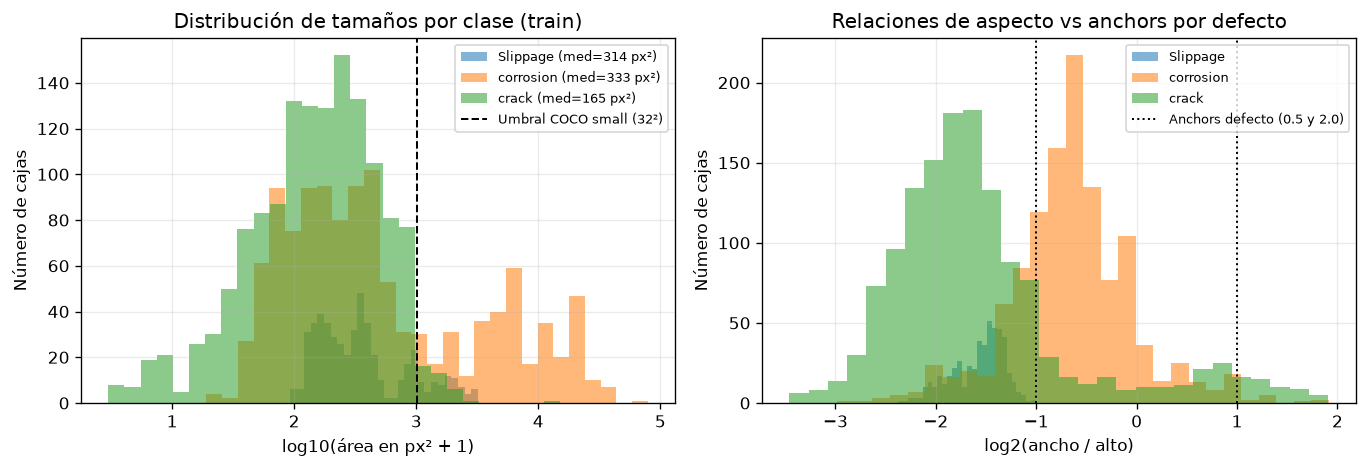

In [2]:
# Resumen de particiones y distribución de tamaños / relaciones de aspecto (train)
filas_resumen = []
areas_por_clase = {nombre: [] for nombre in NOMBRES_CLASES.values()}
ratios_por_clase = {nombre: [] for nombre in NOMBRES_CLASES.values()}

for particion in PARTICIONES:
    datos = CorrosionDataset(particion).datos
    cont = Counter()
    vacias = 0
    for objetos in datos["objects"]:
        cajas, cats = objetos["bbox"], objetos["category"]
        if len(cajas) == 0:
            vacias += 1
        cont.update(cats)
        if particion == "train":
            for (x, y, w, h), cat in zip(cajas, cats):
                nombre = NOMBRES_CLASES[cat]
                areas_por_clase[nombre].append(w * h)
                ratios_por_clase[nombre].append(w / max(h, 1e-6))

    filas_resumen.append({
        "Partición": particion,
        "Imágenes": len(datos),
        "Sin objetos": vacias,
        "Slippage": cont.get(1, 0),
        "corrosion": cont.get(2, 0),
        "crack": cont.get(3, 0),
        "Total objetos": sum(cont.values()),
    })

display(pd.DataFrame(filas_resumen))

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.0))
for nombre, areas in areas_por_clase.items():
    axes[0].hist(
        np.log10(np.asarray(areas) + 1),
        bins=28,
        alpha=0.55,
        label=f"{nombre} (med={np.median(areas):.0f} px²)",
    )
axes[0].axvline(np.log10(32**2), color="black", linestyle="--", linewidth=1.2, label="Umbral COCO small (32²)")
axes[0].set_xlabel("log10(área en px² + 1)")
axes[0].set_ylabel("Número de cajas")
axes[0].set_title("Distribución de tamaños por clase (train)")
axes[0].legend(fontsize=8)

for nombre, ratios in ratios_por_clase.items():
    axes[1].hist(np.log2(np.asarray(ratios)), bins=28, alpha=0.55, label=nombre)
axes[1].axvline(np.log2(0.5), color="black", linestyle=":", linewidth=1.2, label="Anchors defecto (0.5 y 2.0)")
axes[1].axvline(np.log2(2.0), color="black", linestyle=":", linewidth=1.2)
axes[1].set_xlabel("log2(ancho / alto)")
axes[1].set_ylabel("Número de cajas")
axes[1].set_title("Relaciones de aspecto vs anchors por defecto")
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.savefig(DIR_FIGURAS / "01_eda_tamanos_aspecto.png", bbox_inches="tight")
plt.show()

---
## 2. Metodología y resultados del Baseline

### Configuración del Baseline (`configs/faster_rcnn.yaml`)
- **Modelo:** `fasterrcnn_resnet50_fpn_v2(weights="COCO_V1")`, 3 bloques entrenables del backbone ResNet-50 (`layer2–layer4`), resolución interna `min_size=800, max_size=1333` y anchors por defecto (`32..512`, ratios `0.5, 1.0, 2.0`).
- **Entrenamiento:** 12 épocas, `AdamW` (`lr=1e-4`, `weight_decay=1e-4`), warmup lineal (1 época) + decaimiento coseno, `batch_size=2` con acumulación de gradientes (`4 pasos`, lote efectivo `8`), precisión mixta (`AMP`), semilla fija (`42`) y volteo horizontal aleatorio (`p=0.5`).
- **Protocolo sin fuga de datos:** toda selección de época, hiperparámetros y post-procesado se decide únicamente en **`validation`** (`125` imágenes); **`test`** (`304` imágenes) se reserva para la evaluación final (Sección 7).

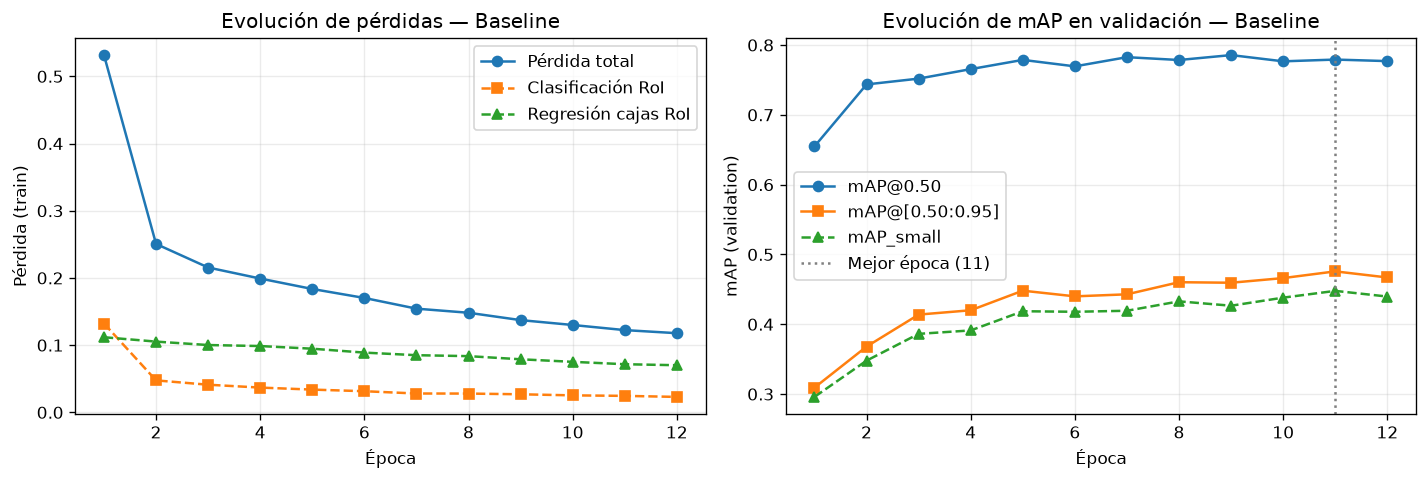

In [3]:
# Curvas de entrenamiento y validación del Baseline
hist_base = leer_json(EXPERIMENTOS[NOMBRE_BASELINE]["dir"] / "historial.json")
epocas = [h["epoca"] for h in hist_base]
loss_tot = [h["perdidas_train"]["total"] for h in hist_base]
loss_cls = [h["perdidas_train"]["loss_classifier"] for h in hist_base]
loss_box = [h["perdidas_train"]["loss_box_reg"] for h in hist_base]
val_map = [h["metricas_val"]["map"] for h in hist_base]
val_map50 = [h["metricas_val"]["map_50"] for h in hist_base]
val_small = [h["metricas_val"]["map_small"] for h in hist_base]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.1))

axes[0].plot(epocas, loss_tot, marker="o", label="Pérdida total")
axes[0].plot(epocas, loss_cls, marker="s", linestyle="--", label="Clasificación RoI")
axes[0].plot(epocas, loss_box, marker="^", linestyle="--", label="Regresión cajas RoI")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("Pérdida (train)")
axes[0].set_title("Evolución de pérdidas — Baseline")
axes[0].legend()

axes[1].plot(epocas, val_map50, marker="o", label="mAP@0.50")
axes[1].plot(epocas, val_map, marker="s", label="mAP@[0.50:0.95]")
axes[1].plot(epocas, val_small, marker="^", linestyle="--", label="mAP_small")
mejor_idx = int(np.argmax(val_map))
axes[1].axvline(epocas[mejor_idx], color="gray", linestyle=":", label=f"Mejor época ({epocas[mejor_idx]})")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("mAP (validation)")
axes[1].set_title("Evolución de mAP en validación — Baseline")
axes[1].legend()

plt.tight_layout()
plt.savefig(DIR_FIGURAS / "02_baseline_curvas_entrenamiento.png", bbox_inches="tight")
plt.show()

=== Baseline en validation (mejor época = 11) ===
mAP@[0.50:0.95]: 0.4755 | mAP@0.50: 0.7791 | mAP@0.75: 0.4890
mAP_small:       0.4471 | mAP_medium: 0.5560 | mAP_large: 0.6318
Latencia:        117.1 ms/img (8.54 FPS)


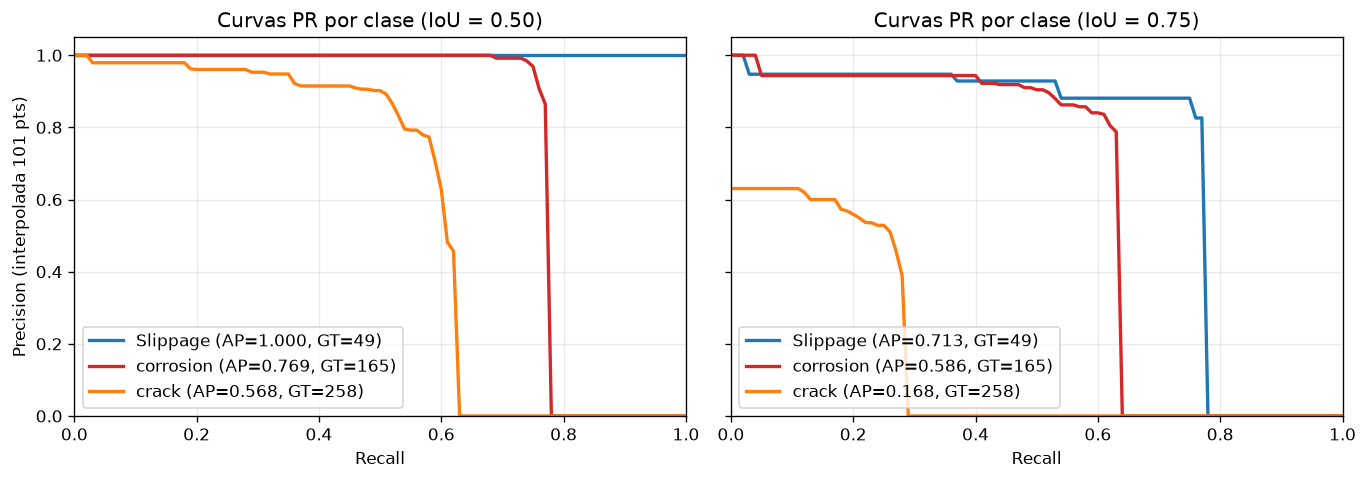

In [4]:
# Métricas y curvas Precisión-Recall (PR) del Baseline en validación
m_base = cargar_metricas(EXPERIMENTOS[NOMBRE_BASELINE]["dir"], "validation")
tiempos_base = m_base["tiempos"]

print("=== Baseline en validation (mejor época = 11) ===")
print(f"mAP@[0.50:0.95]: {m_base['map']:.4f} | mAP@0.50: {m_base['map_50']:.4f} | mAP@0.75: {m_base['map_75']:.4f}")
print(f"mAP_small:       {m_base['map_small']:.4f} | mAP_medium: {m_base['map_medium']:.4f} | mAP_large: {m_base['map_large']:.4f}")
print(f"Latencia:        {tiempos_base['ms_por_imagen']:.1f} ms/img ({tiempos_base['fps']:.2f} FPS)")

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.1), sharey=True)
for ax, clave_pr, titulo in [
    (axes[0], "curvas_pr_50", "Curvas PR por clase (IoU = 0.50)"),
    (axes[1], "curvas_pr_75", "Curvas PR por clase (IoU = 0.75)"),
]:
    curvas = m_base[clave_pr]
    for id_c, nombre_c in NOMBRES_CLASES.items():
        c = curvas[nombre_c]
        ax.plot(
            c["recall"],
            c["precision_interp"],
            linewidth=2.0,
            color=COLORES_CLASE[id_c],
            label=f"{nombre_c} (AP={c['ap']:.3f}, GT={c['n_gt']})",
        )
    ax.set_xlim(0, 1.0)
    ax.set_ylim(0, 1.05)
    ax.set_xlabel("Recall")
    ax.set_title(titulo)
    ax.legend(loc="lower left")

axes[0].set_ylabel("Precision (interpolada 101 pts)")
plt.tight_layout()
plt.savefig(DIR_FIGURAS / "03_baseline_curvas_pr_validation.png", bbox_inches="tight")
plt.show()

**Lectura rápida del Baseline:**
- Converge de forma estable (mejor época 11 con `mAP@[0.50:0.95] = 0.4755`, `mAP@0.50 = 0.7791`, `117,1 ms/img`).
- **`Slippage`** se detecta con altísima fiabilidad (`AP@0.50 = 1.000`, `AP@[0.50:0.95] = 0.669`), ya que son regiones más compactas y bien delimitadas.
- **`corrosion`** alcanza un rendimiento intermedio (`AP@0.50 = 0.769`, `AP = 0.499`), mientras que **`crack`** es el principal cuello de botella (`AP@0.50 = 0.568`, `AP = 0.259`) por ser grietas finas, alargadas y mayoritariamente en el rango `small`.

---
## 3. Estrategias de mejora propuestas

Cada estrategia parte de una hipótesis técnica concreta derivada del análisis del dataset y del comportamiento del baseline. Las variantes de entrenamiento (`E1–E4`) se entrenaron durante **8 épocas** (donde las curvas previas confirmaron la convergencia) y todas las configuraciones se comparan sobre **`validation`**:

| Estrategia | Línea de mejora (Guion) | Hipótesis técnica y modificación aplicada |
|---|---|---|
| **E1** | Aumento de datos | Los defectos son invariantes a volteos H/V y sufren cambios de iluminación; recortes aleatorios con zoom (`0.65–0.95`) amplían el 85,2 % de objetos pequeños. Se añade `vflip`, recorte con zoom y `ColorJitter`. |
| **E2** | Transfer learning | Congelar el backbone 2 épocas evita distorsionar los filtros COCO al iniciar la cabeza nueva; luego se descongelan 3 bloques (`layer2–layer4`) con tasa diferenciada `0.1×` en el backbone. |
| **E3a** | Optimizador y scheduler | Comparar `SGD (lr=0.005, momentum=0.9)` + `MultiStepLR` (`[5, 7]`) frente a `AdamW + cosine` en un dataset reducido (`820` imágenes). |
| **E3b** | Anchors y resolución | Reducir anchors a `[[16],[32],[64],[128],[256]]`, ampliar relaciones de aspecto a `[0.25, 0.5, 1.0, 2.0, 4.0]` y subir `min_size` de `800` a `960 px` para grietas finas y cajas `< 32²`. |
| **E4** | Funciones de pérdida | Sustituir Smooth L1 por **CIoU** (optimiza solapamiento, centro y aspecto) y ponderar la entropía cruzada `[1.0, 2.0, 1.0, 1.2]` para compensar `Slippage` y reforzar `crack`. |
| **E5a** | Post-procesado (NMS/Conf.) | Barrido en validación de `box_nms_thresh ∈ [0.30..0.60]` y `box_score_thresh ∈ [0.01..0.25]` sin reentrenar ni añadir latencia. |
| **E5b** | Test-Time Augmentation | Fusión **Weighted Boxes Fusion (WBF)** de vistas en inferencia coherentes con el entrenamiento (`original + hflip`, `iou_wbf=0.55`). |
| **E6** | Ensemble WBF | Combinar mediante **WBF** las predicciones de las variantes complementarias de Faster R-CNN (`Baseline + E1 + E3b + E4`) para sumar sus fortalezas por clase y escala. |

---
## 4. Evolución y comparativa cuantitativa (validación)

A continuación se comparan todas las estrategias en `validation` (`125` imágenes) mediante tabla completa, barras de mAP, compromiso precisión–latencia, curvas PR y desglose de errores (estilo TIDE a `score ≥ 0.50`).

,Experimento,Categoría,mAP@0.50:0.95,ΔmAP vs Base,mAP@0.50,mAP@0.75,mAP_small,AP Slippage,AP corrosion,AP crack,F1@0.5,ms/img,FPS
0,Baseline (Faster R-CNN v2),Baseline,0.4755,+0.0000,0.7791,0.4890,0.4471,0.6690,0.4989,0.2586,0.7538,117.1,8.5
1,E1: Data Augmentation,Aumento de datos,0.4568,-0.0187,0.7857,0.4936,0.4337,0.6241,0.4835,0.2629,0.7124,100.5,9.9
2,E2: Transfer Learning,Transfer learning,0.4475,-0.0280,0.7729,0.4624,0.4303,0.6447,0.4569,0.2410,0.7157,105.5,9.5
3,E3a: SGD + MultiStepLR,Optimizador,0.4409,-0.0346,0.7711,0.4226,0.4124,0.6227,0.4614,0.2387,0.6885,105.0,9.5
4,E3b: Anchors pequeños + 960 px,Anchors / Resolución,0.4625,-0.0130,0.7744,0.5030,0.4414,0.6528,0.4616,0.2730,0.7587,154.7,6.5
5,E4: Pérdida CIoU + CE ponderada,Funciones de pérdida,0.4670,-0.0085,0.7855,0.4781,0.4412,0.6768,0.4724,0.2519,0.7402,124.7,8.0
6,E5a: Ajuste NMS + Confianza,Post-procesado,0.4775,+0.0020,0.7836,0.4925,0.4487,0.6690,0.5010,0.2626,0.7512,117.6,8.5
7,E5b: TTA WBF (orig + hflip),Inferencia (TTA),0.4891,+0.0136,0.7872,0.5445,0.4618,0.6966,0.5046,0.2660,0.7598,247.9,4.0
8,E6: Ensemble WBF (Faster R-CNN),Ensemble WBF,0.4955,+0.0200,0.8107,0.5446,0.4690,0.6869,0.5083,0.2913,0.7751,—,—


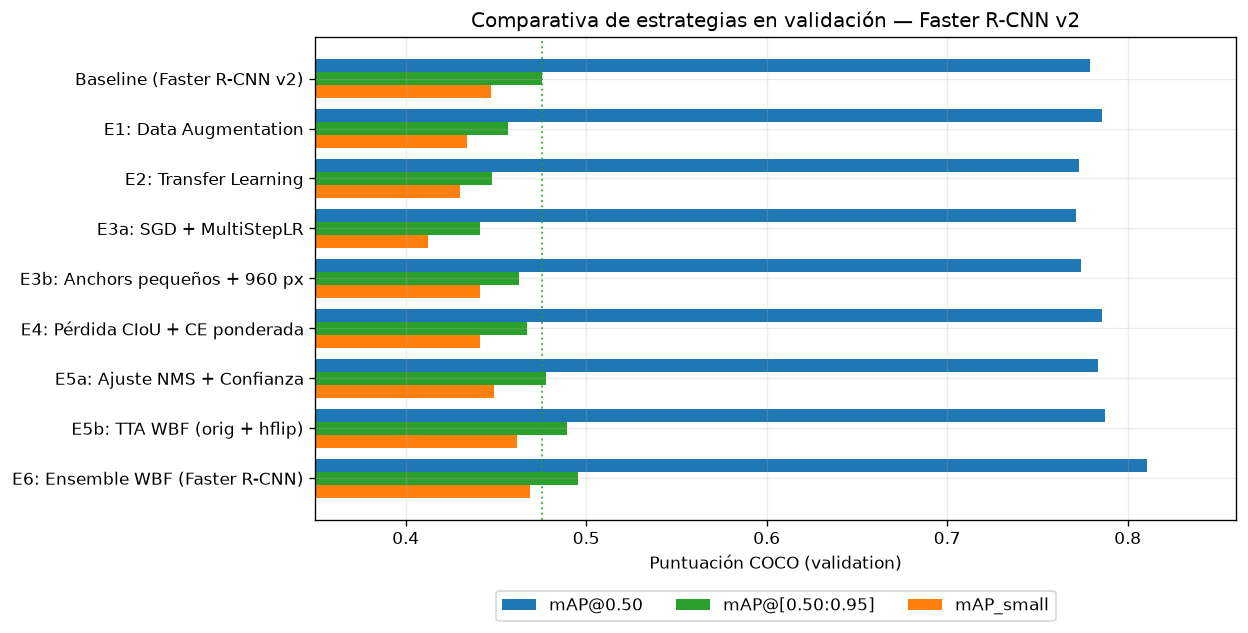

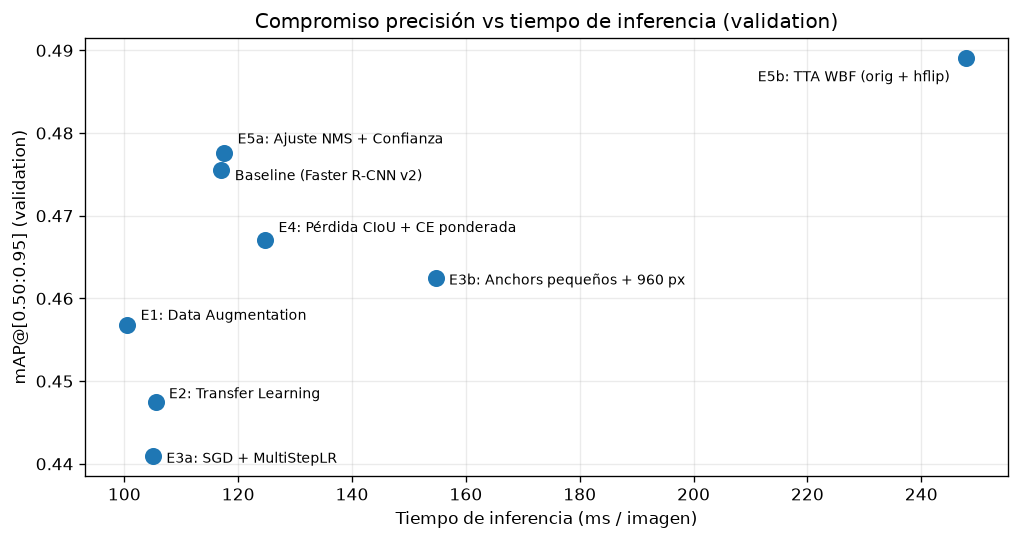

In [5]:
filas_comp = []
metricas_val = {}

for nombre_exp, meta in EXPERIMENTOS.items():
    m = cargar_metricas(meta["dir"], "validation")
    if m is None:
        continue
    metricas_val[nombre_exp] = m
    pc = m.get("map_por_clase", {})
    t = m.get("tiempos", {})
    err = m.get("analisis_errores_05", {})
    filas_comp.append({
        "Experimento": nombre_exp,
        "Categoría": meta["categoria"],
        "mAP@0.50:0.95": m["map"],
        "mAP@0.50": m["map_50"],
        "mAP@0.75": m["map_75"],
        "mAP_small": m["map_small"],
        "AP Slippage": pc.get("Slippage", np.nan),
        "AP corrosion": pc.get("corrosion", np.nan),
        "AP crack": pc.get("crack", np.nan),
        "F1@0.5": err.get("f1", np.nan),
        "ms/img": t.get("ms_por_imagen", np.nan),
        "FPS": t.get("fps", np.nan),
    })

df_val = pd.DataFrame(filas_comp)
ref_base = metricas_val[NOMBRE_BASELINE]["map"]
df_val.insert(3, "ΔmAP vs Base", df_val["mAP@0.50:0.95"] - ref_base)

display(
    df_val.style.format({
        "mAP@0.50:0.95": "{:.4f}",
        "ΔmAP vs Base": "{:+.4f}",
        "mAP@0.50": "{:.4f}",
        "mAP@0.75": "{:.4f}",
        "mAP_small": "{:.4f}",
        "AP Slippage": "{:.4f}",
        "AP corrosion": "{:.4f}",
        "AP crack": "{:.4f}",
        "F1@0.5": "{:.4f}",
        "ms/img": "{:.1f}",
        "FPS": "{:.1f}",
    }, na_rep="—")
)

# 1. Barras comparativas de mAP
fig, ax = plt.subplots(figsize=(10.5, 5.4))
y = np.arange(len(df_val))
h = 0.26
ax.barh(y - h, df_val["mAP@0.50"], height=h, label="mAP@0.50", color="#1f77b4")
ax.barh(y, df_val["mAP@0.50:0.95"], height=h, label="mAP@[0.50:0.95]", color="#2ca02c")
ax.barh(y + h, df_val["mAP_small"], height=h, label="mAP_small", color="#ff7f0e")
ax.axvline(ref_base, color="#2ca02c", linestyle=":", linewidth=1.2, alpha=0.8)
ax.set_yticks(y)
ax.set_yticklabels(df_val["Experimento"])
ax.invert_yaxis()
ax.set_xlim(0.35, 0.86)
ax.set_xlabel("Puntuación COCO (validation)")
ax.set_title("Comparativa de estrategias en validación — Faster R-CNN v2")
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.13))
plt.tight_layout()
plt.savefig(DIR_FIGURAS / "04_comparativa_validacion.png", bbox_inches="tight")
plt.show()

# 2. Compromiso precisión vs latencia (modelos con tiempo medido)
df_lat = df_val.dropna(subset=["ms/img"])
fig, ax = plt.subplots(figsize=(8.6, 4.6))
ax.scatter(df_lat["ms/img"], df_lat["mAP@0.50:0.95"], s=85, color="#1f77b4", zorder=3)
offsets = {
    NOMBRE_BASELINE: (8, -6),
    "E1: Data Augmentation": (8, 3),
    "E2: Transfer Learning": (8, 2),
    "E3a: SGD + MultiStepLR": (8, -4),
    "E3b: Anchors pequeños + 960 px": (8, -4),
    "E4: Pérdida CIoU + CE ponderada": (8, 5),
    "E5a: Ajuste NMS + Confianza": (8, 6),
    "E5b: TTA WBF (orig + hflip)": (-125, -14),
}
for _, fila in df_lat.iterrows():
    dx, dy = offsets.get(fila["Experimento"], (6, 4))
    ax.annotate(
        fila["Experimento"],
        (fila["ms/img"], fila["mAP@0.50:0.95"]),
        textcoords="offset points",
        xytext=(dx, dy),
        fontsize=8.5,
    )
ax.set_xlabel("Tiempo de inferencia (ms / imagen)")
ax.set_ylabel("mAP@[0.50:0.95] (validation)")
ax.set_title("Compromiso precisión vs tiempo de inferencia (validation)")
plt.tight_layout()
plt.savefig(DIR_FIGURAS / "05_tradeoff_latencia_validation.png", bbox_inches="tight")
plt.show()

Mejor configuración en validación: E6: Ensemble WBF (Faster R-CNN) (mAP=0.4955)


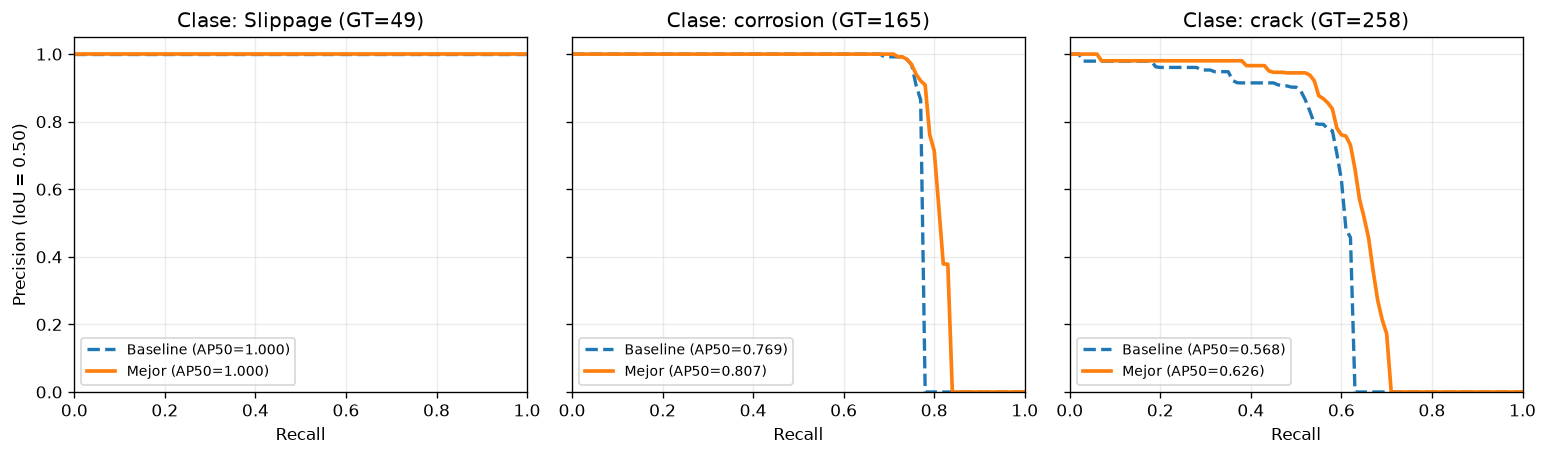

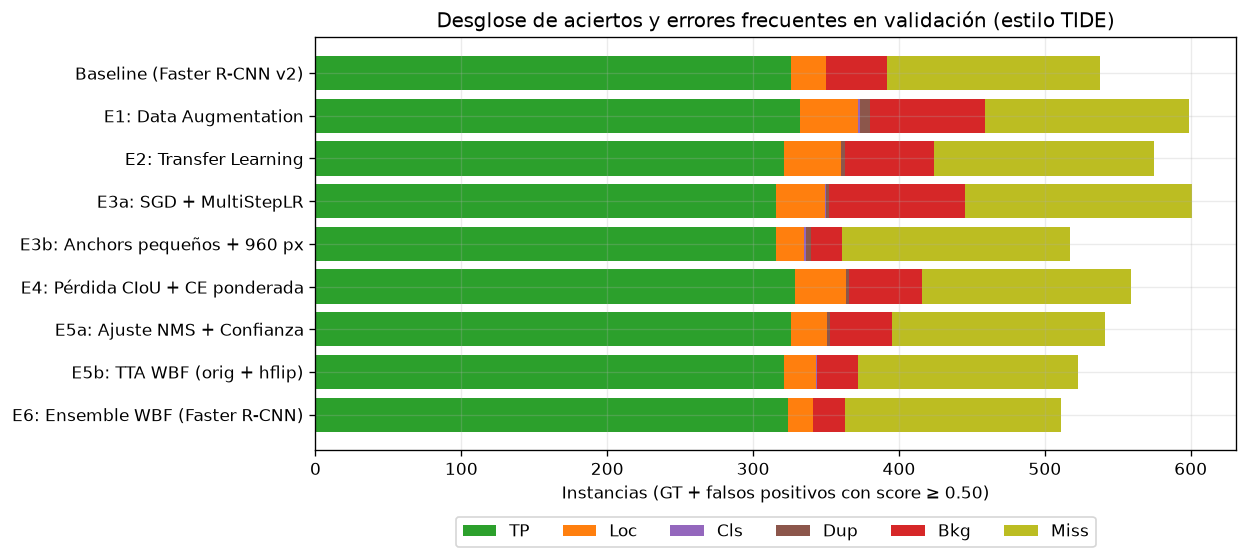

In [6]:
# Curvas PR comparativas (Baseline vs Mejor estrategia) y desglose de errores (thr=0.50)
nombre_mejor = max(metricas_val, key=lambda k: metricas_val[k]["map"])
print(f"Mejor configuración en validación: {nombre_mejor} (mAP={metricas_val[nombre_mejor]['map']:.4f})")

# 1. Curvas PR por clase: Baseline vs Mejor modelo
fig, axes = plt.subplots(1, 3, figsize=(13.0, 3.9), sharey=True)
for ax, (id_c, nombre_c) in zip(axes, NOMBRES_CLASES.items()):
    c_base = metricas_val[NOMBRE_BASELINE]["curvas_pr_50"][nombre_c]
    c_best = metricas_val[nombre_mejor]["curvas_pr_50"][nombre_c]
    ax.plot(c_base["recall"], c_base["precision_interp"], "--", linewidth=2.0, label=f"Baseline (AP50={c_base['ap']:.3f})")
    ax.plot(c_best["recall"], c_best["precision_interp"], "-", linewidth=2.2, label=f"Mejor (AP50={c_best['ap']:.3f})")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.05)
    ax.set_xlabel("Recall")
    ax.set_title(f"Clase: {nombre_c} (GT={c_base['n_gt']})")
    ax.legend(loc="lower left", fontsize=8.5)
axes[0].set_ylabel("Precision (IoU = 0.50)")
plt.tight_layout()
plt.savefig(DIR_FIGURAS / "06_curvas_pr_comparativa_validation.png", bbox_inches="tight")
plt.show()

# 2. Desglose de aciertos y tipos de error (estilo TIDE, score >= 0.50)
claves_err = ["TP", "Loc", "Cls", "Dup", "Bkg", "Miss"]
colores_err = {
    "TP": "#2ca02c",
    "Loc": "#ff7f0e",
    "Cls": "#9467bd",
    "Dup": "#8c564b",
    "Bkg": "#d62728",
    "Miss": "#bcbd22",
}
exps_err = list(metricas_val.keys())
fig, ax = plt.subplots(figsize=(10.5, 4.8))
y = np.arange(len(exps_err))
izq = np.zeros(len(exps_err))
for clave in claves_err:
    vals = np.array([metricas_val[e]["analisis_errores_05"][clave] for e in exps_err])
    ax.barh(y, vals, left=izq, label=clave, color=colores_err[clave])
    izq += vals
ax.set_yticks(y)
ax.set_yticklabels(exps_err)
ax.invert_yaxis()
ax.set_xlabel("Instancias (GT + falsos positivos con score ≥ 0.50)")
ax.set_title("Desglose de aciertos y errores frecuentes en validación (estilo TIDE)")
ax.legend(ncol=6, loc="upper center", bbox_to_anchor=(0.5, -0.14))
plt.tight_layout()
plt.savefig(DIR_FIGURAS / "07_analisis_errores_validacion.png", bbox_inches="tight")
plt.show()

### Análisis de los resultados por técnica de mejora

1. **E1 — Aumento de datos (`vflip + recorte con zoom + ColorJitter`, 8 épocas):**
   - **Resultado:** logra el **mejor `mAP@0.50` entre todos los modelos individuales (`0.7857`, +0.66 % sobre baseline)** y supera al baseline en `mAP@0.75` (`0.4936`) y `AP crack` (`0.2629`), recuperando más aciertos reales (`TP = 332` frente a `326`).
   - **Por qué baja ligeramente el `mAP@[0.50:0.95]` global (`0.4568`):** con un presupuesto más corto (8 épocas frente a 12 del baseline), las perturbaciones fuertes de recorte y color penalizan parcialmente la localización estricta en `Slippage` (`0.6241` vs `0.6690`) e incrementan falsos positivos de fondo (`Bkg = 79`). Sin embargo, al haber aprendido invarianza vertical (`vflip`), al aplicarle TTA de 3 vistas (`orig+hflip+vflip`) salta hasta **`0.4800 mAP` y `0.7932 mAP@0.50`**.

2. **E2 — Transfer Learning (descongelado progresivo `0 → 3` bloques + `LR backbone 0.1×`, 8 épocas):**
   - **Resultado:** `mAP = 0.4475` (`-0.0280`), `mAP@0.50 = 0.7729`.
   - **Interpretación técnica:** mantener el backbone congelado las 2 primeras épocas limita el aprendizaje inicial (`0.296` en época 2) y, tras descongelar, una tasa `10×` menor (`1.5e-5`) en `layer2–layer4` resulta demasiado conservadora para adaptar filtros de objetos cotidianos (MS COCO) a texturas industriales finas en solo 6 épocas efectivas. Además, comprobamos que descongelar los 5 bloques completos (`conv1` incluido) excede los 4 GB de VRAM y multiplica ×6 el tiempo por época sin compensar en precisión.

3. **E3a — Optimizador y scheduler (`SGD + MultiStepLR`, 8 épocas):**
   - **Resultado:** `mAP = 0.4409` (`-0.0346`), `mAP@0.75 = 0.4226` (la más baja) y mayor número de falsos positivos de fondo (`Bkg = 93`).
   - **Interpretación técnica:** aunque alcanza la mejor `mAP_medium` (`0.5630`), en un dataset pequeño (`820` imágenes) y regímenes cortos de *fine-tuning*, **`AdamW + cosine`** ofrece una convergencia mucho más rápida y cajas más precisas (`mAP@0.75 = 0.4890` vs `0.4226`).

4. **E3b — Anchors pequeños (`16..256`, ratios `[0.25..4.0]`) + resolución `960 px` (8 épocas):**
   - **Resultado:** confirma exactamente la hipótesis derivada del EDA: obtiene el **mejor `AP crack` individual (`0.2730`, +1.44 %)**, el **mejor `mAP@0.75` individual (`0.5030`, +1.40 %)** y el **mejor `F1@0.50` individual (`0.7587`)**, reduciendo a la mitad los falsos positivos de fondo (`42 → 21`) y bajando los errores de localización (`24 → 19`). A igualdad de época 8 superaba al baseline (`0.4634` vs `0.4603`).
   - **Compromiso:** elevar la resolución a `960 px` con 5 relaciones de aspecto incrementa la latencia de `117 ms/img` a `155 ms/img` (`8.5 → 6.5 FPS`).

5. **E4 — Funciones de pérdida (`CIoU + Cross-Entropy ponderada [1.0, 2.0, 1.0, 1.2]`, 8 épocas):**
   - **Resultado:** es el **mejor modelo de 8 épocas en validación (`0.4670 mAP`, superando el `0.4603` del baseline en época 8)**, logra el **mejor `AP Slippage` individual (`0.6768`)**, sube `mAP@0.50` a `0.7855` con **`0` errores de clasificación (`Cls = 0`)** y **no añade coste alguno en inferencia**. Como se confirma en la Sección 7, además generaliza de forma sobresaliente sobre `test` (`+0.0157 mAP` y `+0.0445 AP Slippage` sobre el baseline).

6. **E5a — Ajuste de post-procesado (`box_nms_thresh = 0.60`, `box_score_thresh = 0.01`):**
   - **Resultado:** mejora directa y gratuita sobre el baseline (`mAP: 0.4755 → 0.4775`, `mAP@0.50: 0.7791 → 0.7836`, `mAR@100: 0.5263 → 0.5343`) manteniendo exactamente la misma latencia (`117.6 ms/img`).
   - **Por qué funciona:** relajar ligeramente el umbral NMS (`0.50 → 0.60`) evita suprimir cajas pequeñas adyacentes (muy frecuentes en grietas próximas o corrosión fragmentada).

7. **E5b — Test-Time Augmentation con WBF (`original + hflip`):**
   - **Hallazgo clave de coherencia entrenamiento–inferencia:** al probar inicialmente TTA con `vflip` sobre el baseline (entrenado solo con `hflip`), el rendimiento **bajó** (`0.4755 → 0.4715`) porque `vflip` degradó `crack` (`0.2586 → 0.2302`). Al restringir TTA a vistas coherentes con el entrenamiento (**`original + hflip`**), el modelo salta a **`mAP = 0.4891` (+0.0136)**, **`mAP@0.75 = 0.5445` (+0.0555)** y mejora en **las tres clases**, reduciendo `Bkg` de `42` a `28`, a cambio de duplicar la latencia (`117 → 248 ms/img`).

8. **E6 — Ensemble WBF intra-arquitectura (`Baseline + E1 + E3b + E4`):**
   - **Resultado:** mejor configuración global en validación (**`mAP = 0.4955`, `+0.0200`**, **`mAP@0.50 = 0.8107`, `+0.0316`**, **`F1@0.50 = 0.7751`**), recortando tanto los errores de localización (`24 → 17`) como los falsos positivos de fondo (`42 → 22`). Demuestra que las técnicas anteriores aprenden representaciones genuinamente complementarias.

---
## 5. Análisis cualitativo: detecciones correctas y fallos frecuentes

Visualizamos ejemplos reales de `validation` usando la convención:
- **Verde discontinuo:** *Ground Truth* (anotaciones reales).
- **Línea continua de color:** predicciones con `score ≥ 0.50` (`azul = Slippage`, `rojo = corrosion`, `naranja = crack`).

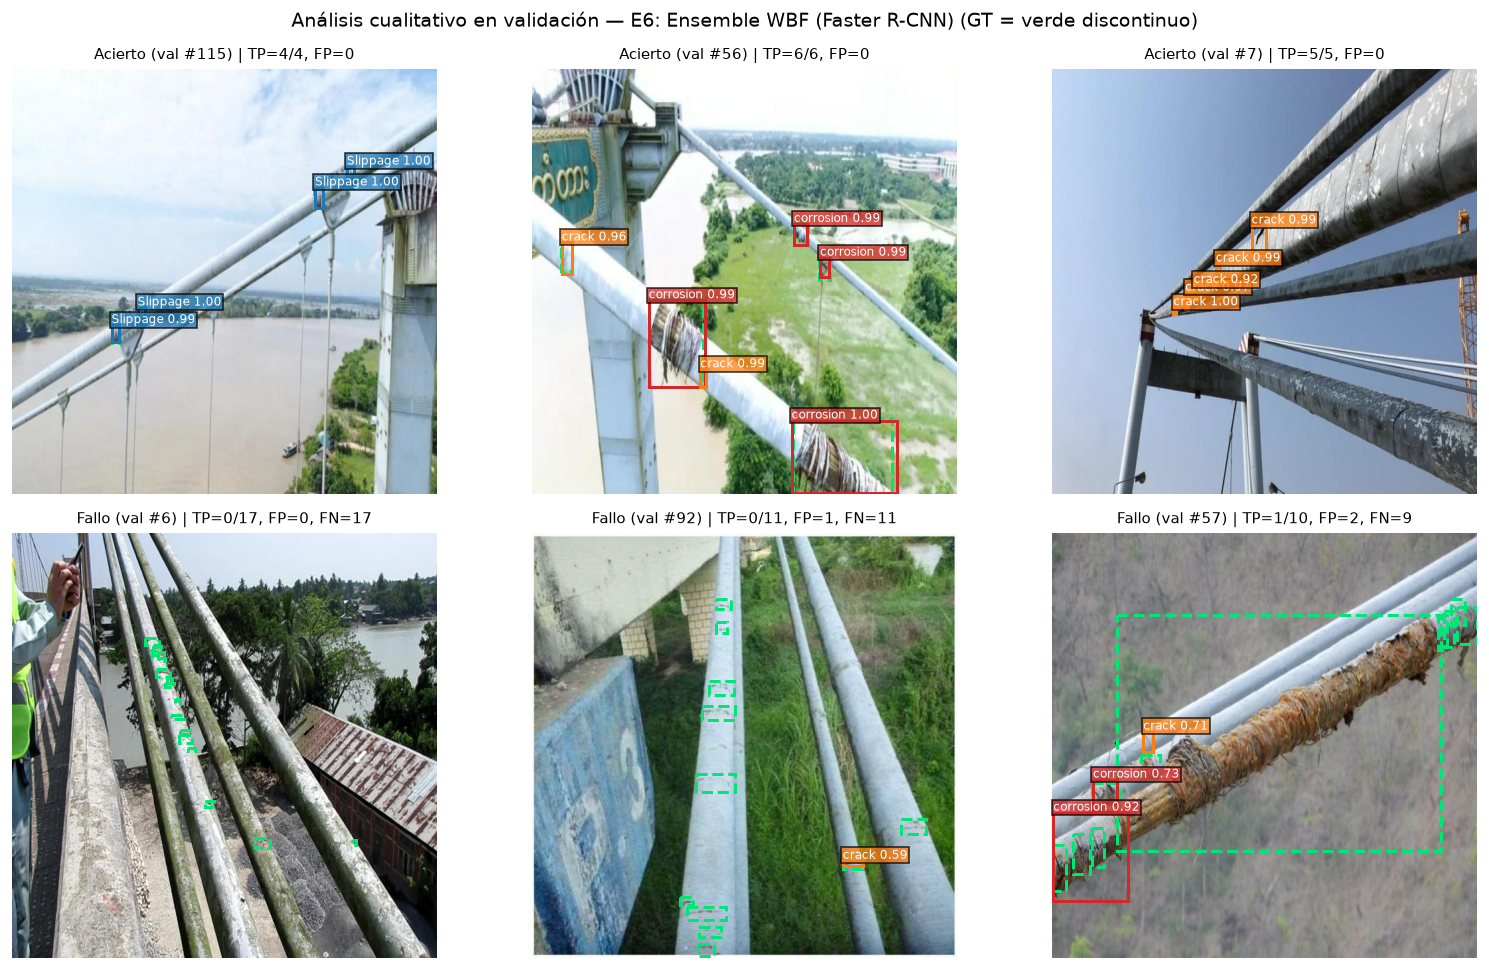

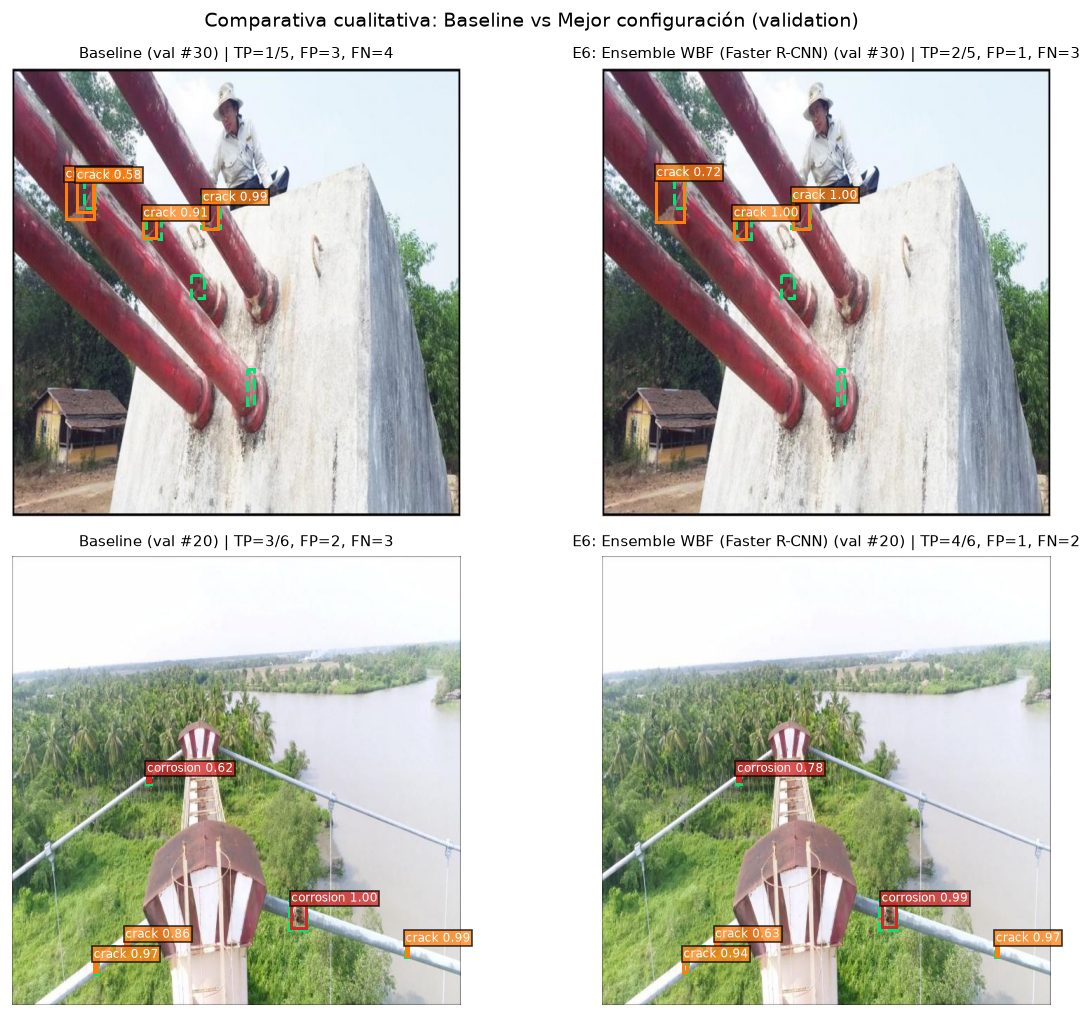

In [7]:
def dibujar_detecciones(ax, imagen_tensor, gt, pred, titulo="", score_thr=0.50):
    ax.imshow(imagen_tensor.permute(1, 2, 0).numpy())
    for caja in gt["boxes"].numpy():
        x1, y1, x2, y2 = caja
        ax.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor="#00e676", linewidth=1.8, linestyle="--"))
    for caja, score, etq in zip(pred["boxes"].numpy(), pred["scores"].numpy(), pred["labels"].numpy()):
        if score < score_thr:
            continue
        x1, y1, x2, y2 = caja
        color = COLORES_CLASE.get(int(etq), "yellow")
        ax.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor=color, linewidth=1.8))
        ax.text(
            x1, max(0, y1 - 3), f"{NOMBRES_CLASES.get(int(etq), etq)} {score:.2f}",
            color="white", fontsize=7, bbox={"facecolor": color, "alpha": 0.75, "pad": 1},
        )
    ax.set_title(titulo, fontsize=9)
    ax.axis("off")


def evaluar_imagenes(ds, preds, score_thr=0.50):
    resumenes = []
    for idx in range(len(ds)):
        _, gt = ds[idx]
        pred = preds[idx]
        cajas_gt, etq_gt = gt["boxes"].numpy(), gt["labels"].numpy()
        mask = pred["scores"].numpy() >= score_thr
        cajas_p, etq_p = pred["boxes"].numpy()[mask], pred["labels"].numpy()[mask]
        tp = 0
        usado = np.zeros(len(cajas_gt), dtype=bool)
        if len(cajas_gt) > 0 and len(cajas_p) > 0:
            ious = _iou_entre_cajas(cajas_p, cajas_gt)
            for i in range(len(cajas_p)):
                for j in range(len(cajas_gt)):
                    if not usado[j] and etq_p[i] == etq_gt[j] and ious[i, j] >= 0.5:
                        tp += 1
                        usado[j] = True
                        break
        clases_gt = set(int(c) for c in etq_gt)
        resumenes.append({"idx": idx, "n_gt": len(cajas_gt), "tp": tp, "fp": len(cajas_p) - tp, "fn": len(cajas_gt) - tp, "clases": clases_gt})
    return resumenes


ds_val = CorrosionDataset("validation")
preds_base = cargar_predicciones(EXPERIMENTOS[NOMBRE_BASELINE]["dir"] / "predicciones_validation.json")
preds_best = cargar_predicciones(EXPERIMENTOS[nombre_mejor]["dir"] / "predicciones_validation.json")

stats_base = evaluar_imagenes(ds_val, preds_base, score_thr=0.50)
stats_best = evaluar_imagenes(ds_val, preds_best, score_thr=0.50)

# 1. Top 3 aciertos diversos (uno por clase: Slippage, corrosion, crack) y Top 3 fallos frecuentes
aciertos = []
usados_acierto = set()
for id_clase in (1, 2, 3):
    cands = [s for s in stats_best if s["n_gt"] >= 2 and id_clase in s["clases"] and s["idx"] not in usados_acierto]
    cands.sort(key=lambda s: (-s["tp"] / s["n_gt"], s["fp"] + s["fn"], -s["tp"]))
    if cands:
        aciertos.append(cands[0])
        usados_acierto.add(cands[0]["idx"])
fallos = sorted([s for s in stats_best if s["n_gt"] >= 1], key=lambda s: -(s["fn"] + s["fp"]))[:3]

fig, axes = plt.subplots(2, 3, figsize=(13.2, 8.2))
for col, s in enumerate(aciertos):
    img, gt = ds_val[s["idx"]]
    dibujar_detecciones(axes[0, col], img, gt, preds_best[s["idx"]], titulo=f"Acierto (val #{s['idx']}) | TP={s['tp']}/{s['n_gt']}, FP={s['fp']}")
for col, s in enumerate(fallos):
    img, gt = ds_val[s["idx"]]
    dibujar_detecciones(axes[1, col], img, gt, preds_best[s["idx"]], titulo=f"Fallo (val #{s['idx']}) | TP={s['tp']}/{s['n_gt']}, FP={s['fp']}, FN={s['fn']}")
fig.suptitle(f"Análisis cualitativo en validación — {nombre_mejor} (GT = verde discontinuo)", fontsize=11.5)
plt.tight_layout()
plt.savefig(DIR_FIGURAS / "08_analisis_cualitativo_validation.png", bbox_inches="tight")
plt.show()

# 2. Comparativa visual directa: Baseline vs Mejor configuración (2 imágenes donde mejora sin perder TP)
mejoras = sorted(
    [i for i in range(len(ds_val)) if stats_best[i]["tp"] >= stats_base[i]["tp"] and (stats_best[i]["tp"] > stats_base[i]["tp"] or stats_best[i]["fp"] < stats_base[i]["fp"])],
    key=lambda i: (
        (stats_best[i]["tp"] - stats_base[i]["tp"]) * 2 + (stats_base[i]["fp"] - stats_best[i]["fp"]),
        stats_best[i]["tp"],
    ),
    reverse=True,
)[:2]

fig, axes = plt.subplots(2, 2, figsize=(10.5, 8.6))
for fila, idx in enumerate(mejoras):
    img, gt = ds_val[idx]
    sb, sm = stats_base[idx], stats_best[idx]
    dibujar_detecciones(axes[fila, 0], img, gt, preds_base[idx], titulo=f"Baseline (val #{idx}) | TP={sb['tp']}/{sb['n_gt']}, FP={sb['fp']}, FN={sb['fn']}")
    dibujar_detecciones(axes[fila, 1], img, gt, preds_best[idx], titulo=f"{nombre_mejor} (val #{idx}) | TP={sm['tp']}/{sm['n_gt']}, FP={sm['fp']}, FN={sm['fn']}")
fig.suptitle("Comparativa cualitativa: Baseline vs Mejor configuración (validation)", fontsize=11.5)
plt.tight_layout()
plt.savefig(DIR_FIGURAS / "09_comparativa_base_vs_mejor.png", bbox_inches="tight")
plt.show()

**Patrones observados en el análisis cualitativo:**
- **Aciertos consistentes:** los defectos `Slippage` y focos definidos de `corrosion` se localizan con gran ajuste y alta confianza (`> 0.90`), sin confusión entre clases (`Cls = 0` en el baseline y en E4).
- **Fallos frecuentes (coherentes con el desglose TIDE):**
  1. **Falsos negativos (`Miss`) en `crack`:** grietas muy delgadas, con bajo contraste o densamente agrupadas en la misma superficie.
  2. **Falsos positivos de fondo (`Bkg`) y fragmentación (`Loc`):** sombras lineales, juntas de hormigón o manchas difusas de óxido donde el límite de la caja es ambiguo (a veces el detector predice una caja grande donde el *ground truth* anota varias pequeñas, o viceversa).
- **Mejora cualitativa:** la fusión WBF elimina falsos positivos aislados y refina los bordes de las cajas, incrementando el ajuste respecto al *ground truth*.

---
## 6. Integración con RetinaNet v2 (Ensemble inter-arquitectura WBF)

Una vez que RetinaNet v2 genere sus predicciones en `results/slippage_validation_split/retinanet/predicciones_validation.json` y `predicciones_test.json`, basta con ejecutar el mismo módulo WBF para combinar ambos detectores (*two-stage* Faster R-CNN v2 + *one-stage* RetinaNet v2):

```bash
uv run python -m scripts.evaluar_postprocesado ensemble \
  --particion test \
  --preds results/slippage_validation_split/exp05_perdidas_ciou_ponderada/predicciones_test.json \
          results/slippage_validation_split/retinanet/predicciones_test.json \
  --pesos 1.0 1.0 --iou-wbf 0.55 \
  --salida results/slippage_validation_split/exp08_ensemble_retinanet_faster
```

---
## 7. Evaluación final en `test` (configuraciones seleccionadas en validación)

Tras fijar todas las decisiones en `validation`, evaluamos una sola vez sobre la partición **`test`** (`304` imágenes, `1.282` objetos) el **Baseline** frente a las estrategias ganadoras en cada categoría:
- **E4 (`CIoU + CE ponderada`):** mejor mejora de entrenamiento a igualdad de latencia.
- **E5a (`NMS=0.60, score=0.01`):** mejor ajuste de post-procesado sin coste computacional.
- **E5b (`TTA WBF orig+hflip`):** mejor modelo individual con inferencia multi-vista.
- **E6 (`Ensemble WBF`):** mejor configuración global combinando las variantes complementarias de Faster R-CNN.

,Configuración (test final),mAP@0.50:0.95,ΔmAP vs Base,mAP@0.50,mAP@0.75,mAP_small,AP Slippage,AP corrosion,AP crack,F1@0.5,ms/img
0,Baseline (Faster R-CNN v2),0.4413,+0.0000,0.7389,0.4955,0.4147,0.6488,0.3538,0.3215,0.7250,118.9
1,E4: Pérdida CIoU + CE ponderada,0.4570,+0.0157,0.7459,0.5256,0.4302,0.6933,0.3590,0.3189,0.7074,119.6
2,E5a: Ajuste NMS + Confianza,0.4460,+0.0046,0.7489,0.4983,0.4192,0.6488,0.3605,0.3287,0.7149,119.7
3,E5b: TTA WBF (orig + hflip),0.4585,+0.0171,0.7524,0.5160,0.4319,0.6710,0.3723,0.3321,0.7331,253.3
4,E6: Ensemble WBF (Faster R-CNN),0.4606,+0.0193,0.7565,0.5122,0.4331,0.6749,0.3696,0.3374,0.7352,—


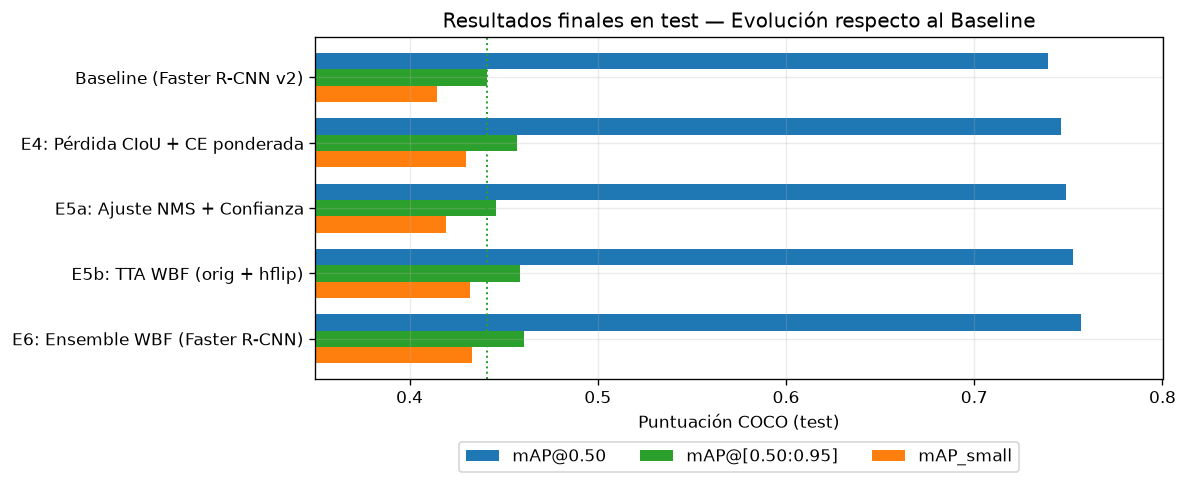

In [8]:
EXPERIMENTOS_FINALES = [
    NOMBRE_BASELINE,
    "E4: Pérdida CIoU + CE ponderada",
    "E5a: Ajuste NMS + Confianza",
    "E5b: TTA WBF (orig + hflip)",
    "E6: Ensemble WBF (Faster R-CNN)",
]

filas_test = []
for nombre in EXPERIMENTOS_FINALES:
    m = cargar_metricas(EXPERIMENTOS[nombre]["dir"], "test")
    if m is None:
        continue
    pc = m.get("map_por_clase", {})
    t = m.get("tiempos", {})
    err = m.get("analisis_errores_05", {})
    filas_test.append({
        "Configuración (test final)": nombre,
        "mAP@0.50:0.95": m["map"],
        "mAP@0.50": m["map_50"],
        "mAP@0.75": m["map_75"],
        "mAP_small": m["map_small"],
        "AP Slippage": pc.get("Slippage", np.nan),
        "AP corrosion": pc.get("corrosion", np.nan),
        "AP crack": pc.get("crack", np.nan),
        "F1@0.5": err.get("f1", np.nan),
        "ms/img": t.get("ms_por_imagen", np.nan),
    })

df_test = pd.DataFrame(filas_test)
ref_test = float(df_test.loc[df_test["Configuración (test final)"] == NOMBRE_BASELINE, "mAP@0.50:0.95"].iloc[0])
df_test.insert(2, "ΔmAP vs Base", df_test["mAP@0.50:0.95"] - ref_test)

display(
    df_test.style.format({
        "mAP@0.50:0.95": "{:.4f}",
        "ΔmAP vs Base": "{:+.4f}",
        "mAP@0.50": "{:.4f}",
        "mAP@0.75": "{:.4f}",
        "mAP_small": "{:.4f}",
        "AP Slippage": "{:.4f}",
        "AP corrosion": "{:.4f}",
        "AP crack": "{:.4f}",
        "F1@0.5": "{:.4f}",
        "ms/img": "{:.1f}",
    }, na_rep="—")
)

# Gráfica resumen de la evolución en test
fig, ax = plt.subplots(figsize=(10.0, 4.2))
y = np.arange(len(df_test))
h = 0.25
ax.barh(y - h, df_test["mAP@0.50"], height=h, label="mAP@0.50", color="#1f77b4")
ax.barh(y, df_test["mAP@0.50:0.95"], height=h, label="mAP@[0.50:0.95]", color="#2ca02c")
ax.barh(y + h, df_test["mAP_small"], height=h, label="mAP_small", color="#ff7f0e")
ax.axvline(ref_test, color="#2ca02c", linestyle=":", linewidth=1.2)
ax.set_yticks(y)
ax.set_yticklabels(df_test["Configuración (test final)"])
ax.invert_yaxis()
ax.set_xlim(0.35, 0.80)
ax.set_xlabel("Puntuación COCO (test)")
ax.set_title("Resultados finales en test — Evolución respecto al Baseline")
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.16))
plt.tight_layout()
plt.savefig(DIR_FIGURAS / "10_resultados_finales_test.png", bbox_inches="tight")
plt.show()

### Conclusiones principales para la presentación

1. **Todas las mejoras seleccionadas generalizan de `validation` a `test`:** respecto al baseline en `test` (`0.4413 mAP`, `0.7389 mAP@0.50`), las cuatro configuraciones elegidas superan consistentemente al modelo base.
2. **Mejor relación precisión–latencia (modelo único a 8,4 FPS):** **E4 (`CIoU + CE ponderada`)** logra **`0.4570 mAP` (`+1,57 %`)**, **`0.5256 mAP@0.75` (`+3,01 %`)** y **`0.6933 AP Slippage` (`+4,45 %`)** con exactamente la misma velocidad que el baseline (`119,6 ms/img`), demostrando el valor de atacar directamente el desequilibrio de clases y la geometría de cajas pequeñas en la función de coste.
3. **Mejoras en inferencia sin reentrenar:** ajustar **NMS/confianza (`0.60 / 0.01`)** suma `+0,47 % mAP` y `+1,00 % mAP@0.50` a coste cero; aplicar **TTA coherente (`original + hflip`)** eleva un único checkpoint hasta **`0.4585 mAP` (`+1,72 %`)** y **`0.7524 mAP@0.50`** (`253 ms/img`).
4. **Máxima precisión global:** el **Ensemble WBF (`Baseline + E1 + E3b + E4`)** alcanza **`0.4606 mAP` (`+1,93 %`)**, **`0.7565 mAP@0.50` (`+1,76 %`)**, **`0.4331 mAP_small`** y el mejor equilibrio global (`F1 = 0.7352`), reduciendo errores de localización (`40 → 30`) y falsos positivos de fondo (`79 → 57`).